In [2]:
import matplotlib.pyplot as plt  
import numpy as np
import os
import sys
import pandas as pd
import geopandas as gpd
import yaml

In [3]:
def process_key(key):
    # Convert string key to a tuple
    return safe_tuple_parser(key)

def process_value(value):
    # Convert string value to float
    return float(value)

def safe_tuple_parser(key):
    """
    Safely parses string representations of nested tuples into actual Python tuples.
    Example: "(2024, (1, 7, 0), (1, 8), 2024)" -> (2024, (1, 7, 0), (1, 8), 2024)
    """
    import ast  # Abstract Syntax Tree module for safe literal evaluation

    # Remove outer quotes if present and use `ast.literal_eval`
    try:
        return ast.literal_eval(key)
    except (SyntaxError, ValueError) as e:
        raise ValueError(f"Failed to parse key: {key}") from e

def read_data(case_study_name, input_folder_name, variables_to_read, run_id):
    current_path = os.getcwd()
    print("Current path:", current_path)
    file_results = os.path.normpath(current_path + "/results")
    print("File results:", os.path.normpath(file_results))
    file_path = os.path.join(current_path, "/results")
    print(file_path)
    # Normalize the path
    normalized_path = os.path.normpath(file_path)
    print("Normalized path:", normalized_path)

    # Reading input data from the folder
    folder_input = os.path.normpath(current_path + "/input_data/" + input_folder_name)
    input_data = {}
    for file_name in os.listdir(folder_input):
        if file_name.endswith(".yaml"):
            key_name = os.path.splitext(file_name)[0]  # Extract the key name from the file name
            if key_name != "SpatialFlexibilityEdges":  # Avoid overwriting existing keys
                with open(os.path.join(folder_input, file_name)) as file:
                    input_data[key_name] = yaml.safe_load(file)

    output_data = {}
    for variable in variables_to_read:
        file_name = os.path.normpath(file_results + "/" + input_folder_name + "/" + case_study_name + f"_{variable}_dict.yaml")
        with open(file_name) as file:
            data_dict = yaml.safe_load(file)
        output_data[variable] = {process_key(key): process_value(value) for key, value in data_dict.items()}
        print(f"Loaded {file_name} into output_data under variable '{variable}'")

    return input_data, output_data


In [4]:
case_study_names = ["case_20251106_112933"]
runs = ["case_20251106_112933_cs_2025-11-06_13-30-15"]
case_study_name_label = [
    "Shift to rail"
]

In [5]:
# Load data for all runs
variables_to_read = [
    "f",
     "h", "h_plus", "h_exist", "h_minus", "s", "travel_time", "extra_break_time"
    #"q_fuel_infr_plus", "soc", 
]

loaded_runs = {}
for ij in range(len(case_study_names)):
    case_study_name = case_study_names[ij]
    results_file = runs[ij]
    input_data, output_data = read_data(results_file, case_study_name, variables_to_read, ij)
    loaded_runs[case_study_name] = {
        "input_data": input_data,
        "output_data": output_data
    }

print(f"✓ Loaded {len(loaded_runs)} run(s)")
print(f"  Case: {case_study_names[0]}")
print(f"  Run ID: {runs[0]}")

Current path: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM
File results: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results
c:/results
Normalized path: c:\results
Loaded c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\case_20251106_112933\case_20251106_112933_cs_2025-11-06_13-30-15_f_dict.yaml into output_data under variable 'f'
Loaded c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\case_20251106_112933\case_20251106_112933_cs_2025-11-06_13-30-15_h_dict.yaml into output_data under variable 'h'
Loaded c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\case_20251106_112933\case_20251106_112933_cs_2025-11-0

# Break Times Analysis

This notebook analyzes mandatory break enforcement by comparing:
1. **Mandatory break requirements** - Minimum travel time with breaks per vehicle
2. **Actual travel time** - Total travel time at break locations (includes breaks + charging)
3. **Extra break time (slack)** - Additional time added to meet constraints


In [6]:
# Extract data for analysis
case_name = case_study_names[0]
input_data = loaded_runs[case_name]["input_data"]
output_data = loaded_runs[case_name]["output_data"]

travel_time = output_data["travel_time"]
extra_break_time = output_data["extra_break_time"]
flow = output_data["f"]

mandatory_breaks = input_data["MandatoryBreaks"]
paths = input_data["Path"]
techvehicles = input_data["TechVehicle"]
model_params = input_data["Model"]

print(f"Loaded data for case: {case_name}")
print(f"Mandatory breaks: {len(mandatory_breaks)}")
print(f"Travel time entries: {len(travel_time)}")
print(f"Extra break time entries: {len(extra_break_time)}")

Loaded data for case: case_20251106_112933
Mandatory breaks: 949
Travel time entries: 59791
Extra break time entries: 4429


In [7]:
# Create lookup dictionaries
path_dict = {p["id"]: p for p in paths}
tv_dict = {tv["id"]: tv for tv in techvehicles}

# Get model parameters
g_init = model_params["y_init"] - model_params["pre_y"]
time_step = model_params["time_step"]
y_init = model_params["y_init"]

# Analyze break timing vs requirements
break_analysis = []

for mb in mandatory_breaks:
    path_id = mb["path_id"]
    break_location = mb["latest_geo_id"]
    time_with_breaks = mb["time_with_breaks"]  # Min time per vehicle (hours)
    
    path = path_dict.get(path_id)
    if not path:
        continue
    
    # Check travel time at this break location
    for key, tt_value in travel_time.items():
        year, prkg, tv_id, gen = key
        prod_id, od_id, key_path_id, geo_id = prkg
        
        if key_path_id == path_id and geo_id == break_location:
            # Get flow to calculate number of vehicles
            flow_key = (year, (prod_id, od_id, path_id), (1, tv_id), gen)  # mode=1 for road
            flow_val = flow.get(flow_key, 0)
            
            if flow_val < 1e-6:
                continue
            
            # Calculate number of vehicles
            tv = tv_dict.get(tv_id)
            if not tv:
                continue
            
            gen_idx = gen - g_init
            W = tv["W"][gen_idx]
            AnnualRange = tv["AnnualRange"][gen_idx]
            
            num_vehicles = (path["length"] / (W * AnnualRange)) * 1000 * flow_val
            
            # Calculate required minimum time
            min_required = time_with_breaks * num_vehicles
            
            # Get extra break time (slack)
            extra_key = (year, prkg, tv_id, gen)
            extra_time = extra_break_time.get(extra_key, 0)
            
            # Calculate break duration per vehicle
            break_duration_per_vehicle = extra_time / num_vehicles if num_vehicles > 0 else 0
            
            break_analysis.append({
                "path_id": path_id,
                "break_location": break_location,
                "year": year,
                "generation": gen,
                "vehicle_type": tv_id,
                "num_vehicles": num_vehicles,
                "min_required_time": min_required,  # Total fleet minimum (hours)
                "actual_travel_time": tt_value,  # Total fleet actual (hours)
                "extra_break_time": extra_time,  # Total fleet slack (hours)
                "slack_per_vehicle": break_duration_per_vehicle,  # Per vehicle (hours)
                "time_difference": tt_value - min_required,  # Surplus time
                "compliance": "OK" if tt_value >= min_required * 0.99 else "VIOLATION"
            })

df_breaks = pd.DataFrame(break_analysis)
print(f"\nAnalyzed {len(df_breaks)} break locations")
print(f"Compliant: {(df_breaks['compliance'] == 'OK').sum()}")
print(f"Violations: {(df_breaks['compliance'] == 'VIOLATION').sum()}")


Analyzed 11325 break locations
Compliant: 11325
Violations: 0


In [20]:
# Summary statistics
print("="*80)
print("BREAK TIMING ANALYSIS SUMMARY")
print("="*80)

print(f"\nTotal break locations analyzed: {len(df_breaks)}")
print(f"\nFleet statistics:")
print(f"  Average vehicles per route: {df_breaks['num_vehicles'].mean():.2f}")
print(f"  Min vehicles: {df_breaks['num_vehicles'].min():.2f}")
print(f"  Max vehicles: {df_breaks['num_vehicles'].max():.2f}")

print(f"\nTime requirements (fleet totals, hours):")
print(f"  Avg required time: {df_breaks['min_required_time'].mean():.2f}")
print(f"  Avg actual time: {df_breaks['actual_travel_time'].mean():.2f}")
print(f"  Avg extra slack: {df_breaks['extra_break_time'].mean():.2f}")

print(f"\nBreak duration per vehicle (hours):")
print(f"  Mean: {df_breaks['slack_per_vehicle'].mean():.2f}")
print(f"  Median: {df_breaks['slack_per_vehicle'].median():.2f}")
print(f"  Min: {df_breaks['slack_per_vehicle'].min():.2f}")
print(f"  Max: {df_breaks['slack_per_vehicle'].max():.2f}")
print(f"  Std: {df_breaks['slack_per_vehicle'].std():.2f}")

print(f"\nCompliance:")
print(f"  OK: {(df_breaks['compliance'] == 'OK').sum()} ({(df_breaks['compliance'] == 'OK').sum()/len(df_breaks)*100:.1f}%)")
print(f"  VIOLATION: {(df_breaks['compliance'] == 'VIOLATION').sum()} ({(df_breaks['compliance'] == 'VIOLATION').sum()/len(df_breaks)*100:.1f}%)")

BREAK TIMING ANALYSIS SUMMARY

Total break locations analyzed: 11325

Fleet statistics:
  Average vehicles per route: 46.62
  Min vehicles: 0.08
  Max vehicles: 1115.92

Time requirements (fleet totals, hours):
  Avg required time: 352.27
  Avg actual time: 469.96
  Avg extra slack: 58.99

Break duration per vehicle (hours):
  Mean: 1.40
  Median: 0.00
  Min: 0.00
  Max: 22.16
  Std: 3.57

Compliance:
  OK: 11325 (100.0%)
  VIOLATION: 0 (0.0%)


In [21]:
# Break Timing Analysis: First Mandatory Break (4.5 hour rule)
# Filter for num_drivers=1, break_number=1, event_type="B"

first_breaks = [mb for mb in mandatory_breaks 
                if mb.get("num_drivers") == 1 
                and mb.get("break_number") == 1 
                and mb.get("event_type") == "B"]

print(f"Found {len(first_breaks)} first mandatory breaks (4.5h rule)")

# Analyze break timing, duration, and charging
break_timing_data = []

for mb in first_breaks:
    path_id = mb["path_id"]
    break_location = mb["latest_geo_id"]
    cumulative_driving_time = mb["cumulative_driving_time"]  # When break occurs (hours)
    time_with_breaks = mb["time_with_breaks"]  # Time including mandatory break
    min_break_duration = time_with_breaks - cumulative_driving_time  # Minimum required (0.75h)
    
    path = path_dict.get(path_id)
    if not path:
        continue
    
    # Get actual break duration and charging time from optimization results
    for key, tt_value in travel_time.items():
        year, prkg, tv_id, gen = key
        prod_id, od_id, key_path_id, geo_id = prkg
        
        if key_path_id == path_id and geo_id == break_location:
            # Get flow to calculate number of vehicles
            flow_key = (year, (prod_id, od_id, path_id), (1, tv_id), gen)
            flow_val = flow.get(flow_key, 0)
            
            if flow_val < 1e-6:
                continue
            
            # Calculate number of vehicles
            tv = tv_dict.get(tv_id)
            if not tv:
                continue
            
            gen_idx = gen - g_init
            W = tv["W"][gen_idx]
            AnnualRange = tv["AnnualRange"][gen_idx]
            peak_fueling = tv["peak_fueling"][gen_idx]  # kW charging power
            
            num_vehicles = (path["length"] / (W * AnnualRange)) * 1000 * flow_val
            
            # Get extra slack from extra_break_time
            extra_key = (year, prkg, tv_id, gen)
            extra_time = extra_break_time.get(extra_key, 0)
            extra_slack = extra_time / num_vehicles if num_vehicles > 0 else 0
            
            # Get charging time at this break location
            # FIXED: s variable has 5 dimensions: (year, (p,r,k,g), tv_id, (f,l), gen)
            charging_time_total = 0.0
            for s_key, s_value in output_data["s"].items():
                # Unpack all 5 dimensions
                s_year, s_prkg, s_tv_id, s_f_l, s_gen = s_key
                s_prod_id, s_od_id, s_path_id, s_geo_id = s_prkg
                
                if (s_year == year and s_path_id == path_id and 
                    s_geo_id == geo_id and s_tv_id == tv_id and s_gen == gen):
                    # Convert kWh to hours: kWh / kW
                    charging_time_total += (s_value * 1000) / peak_fueling if peak_fueling > 0 else 0
            
            charging_time_per_vehicle = charging_time_total / num_vehicles if num_vehicles > 0 else 0
            
            # CORRECTED: Actual break duration = mandatory + slack
            actual_break_duration = min_break_duration + extra_slack
            
            # Total time at break location = break + charging
            total_stop_time = actual_break_duration + charging_time_per_vehicle
            
            break_timing_data.append({
                "path_id": path_id,
                "year": year,
                "generation": gen,
                "vehicle_type": tv_id,
                "cumulative_driving_time": cumulative_driving_time,  # When break occurs
                "min_break_duration": min_break_duration,  # Minimum required (0.75h)
                "extra_slack": extra_slack,  # Break slack from optimizer
                "actual_break_duration": actual_break_duration,  # Total break = mandatory + slack
                "charging_time": charging_time_per_vehicle,  # Charging time per vehicle
                "total_stop_time": total_stop_time,  # Break + charging
                "num_vehicles": num_vehicles
            })

df_timing = pd.DataFrame(break_timing_data)
print(f"Analyzed {len(df_timing)} break timing entries")
print(f"\\nBreak timing statistics:")
print(f"  Avg driving time before break: {df_timing['cumulative_driving_time'].mean():.2f}h")
print(f"  Min driving time before break: {df_timing['cumulative_driving_time'].min():.2f}h")
print(f"  Max driving time before break: {df_timing['cumulative_driving_time'].max():.2f}h")
print(f"\\nBreak duration statistics:")
print(f"  Required minimum: {df_timing['min_break_duration'].mean():.2f}h (45 min)")
print(f"  Avg extra slack: {df_timing['extra_slack'].mean():.2f}h ({df_timing['extra_slack'].mean()*60:.1f} min)")
print(f"  Avg actual break: {df_timing['actual_break_duration'].mean():.2f}h ({df_timing['actual_break_duration'].mean()*60:.1f} min)")
print(f"  Min actual break: {df_timing['actual_break_duration'].min():.2f}h")
print(f"  Max actual break: {df_timing['actual_break_duration'].max():.2f}h")
print(f"\\nCharging time statistics:")
print(f"  Avg charging time: {df_timing['charging_time'].mean():.2f}h ({df_timing['charging_time'].mean()*60:.1f} min)")
print(f"  Max charging time: {df_timing['charging_time'].max():.2f}h ({df_timing['charging_time'].max()*60:.1f} min)")
print(f"  Routes with charging: {(df_timing['charging_time'] > 0.01).sum()} ({(df_timing['charging_time'] > 0.01).sum()/len(df_timing)*100:.1f}%)")
print(f"\\nTotal stop time (break + charging):")
print(f"  Avg total: {df_timing['total_stop_time'].mean():.2f}h ({df_timing['total_stop_time'].mean()*60:.1f} min)")
print(f"  Max total: {df_timing['total_stop_time'].max():.2f}h ({df_timing['total_stop_time'].max()*60:.1f} min)")


Found 582 first mandatory breaks (4.5h rule)
Analyzed 6971 break timing entries
\nBreak timing statistics:
  Avg driving time before break: 4.11h
  Min driving time before break: 1.33h
  Max driving time before break: 5.43h
\nBreak duration statistics:
  Required minimum: 0.75h (45 min)
  Avg extra slack: 1.55h (92.7 min)
  Avg actual break: 2.30h (137.7 min)
  Min actual break: 0.75h
  Max actual break: 22.91h
\nCharging time statistics:
  Avg charging time: 0.83h (49.9 min)
  Max charging time: 10.47h (628.3 min)
  Routes with charging: 5738 (82.3%)
\nTotal stop time (break + charging):
  Avg total: 3.13h (187.6 min)
  Max total: 22.91h (1374.5 min)


In [22]:
# ==============================================================================
# FILTER FERRY ROUTES FROM VISUALIZATION
# ==============================================================================
import yaml

# Load ferry routes (paths with edges >800km - likely ferries)
with open('ferry_routes.yaml', 'r') as f:
    ferry_info = yaml.safe_load(f)

ferry_path_ids = set(ferry_info['ferry_paths'])

print("="*80)
print("FILTERING FERRY ROUTES FROM BREAK TIME VISUALIZATION")
print("="*80)
print(f"\nFerry routes with edges >800km: {len(ferry_path_ids)}")
print(f"Ferry path IDs: {sorted(ferry_path_ids)}")
print(f"  (These are Germany-Sweden and Norway coastal ferries)")

# Check if path_id column exists
if 'path_id' not in df_timing.columns:
    print("\n[WARNING] 'path_id' column not found!")
    print("Available columns:", list(df_timing.columns))
else:
    # Save original
    df_timing_original = df_timing.copy()

    # Filter out ferry routes
    df_timing = df_timing[~df_timing['path_id'].isin(ferry_path_ids)].copy()

    print(f"\nFiltering results:")
    print(f"  Original: {len(df_timing_original)} routes")
    print(f"  Filtered: {len(df_timing)} routes")
    print(f"  Removed:  {len(df_timing_original) - len(df_timing)} routes ({(len(df_timing_original) - len(df_timing))/len(df_timing_original)*100:.1f}%)")

    # Show impact on statistics
    if len(df_timing) > 0:
        print(f"\nImpact on stop time statistics:")
        print(f"  Original mean: {df_timing_original['total_stop_time'].mean():.2f}h")
        print(f"  Filtered mean: {df_timing['total_stop_time'].mean():.2f}h")

        print(f"\n  Original max: {df_timing_original['total_stop_time'].max():.2f}h")
        print(f"  Filtered max: {df_timing['total_stop_time'].max():.2f}h")

        # Check extreme values
        extreme_orig = len(df_timing_original[df_timing_original['total_stop_time'] > 10.0])
        extreme_filt = len(df_timing[df_timing['total_stop_time'] > 10.0])

        print(f"\n  Routes with stop time >10h:")
        print(f"    Original: {extreme_orig}")
        print(f"    Filtered: {extreme_filt}")
        print(f"    Removed:  {extreme_orig - extreme_filt}")

print("\n" + "="*80)
print("Ferry routes excluded - now showing only truck driving routes")
print("="*80)



FILTERING FERRY ROUTES FROM BREAK TIME VISUALIZATION

Ferry routes with edges >800km: 6
Ferry path IDs: [2110, 2111, 2179, 5129, 5289, 5409]
  (These are Germany-Sweden and Norway coastal ferries)

Filtering results:
  Original: 6971 routes
  Filtered: 6894 routes
  Removed:  77 routes (1.1%)

Impact on stop time statistics:
  Original mean: 3.13h
  Filtered mean: 3.06h

  Original max: 22.91h
  Filtered max: 22.01h

  Routes with stop time >10h:
    Original: 257
    Filtered: 222
    Removed:  35

Ferry routes excluded - now showing only truck driving routes


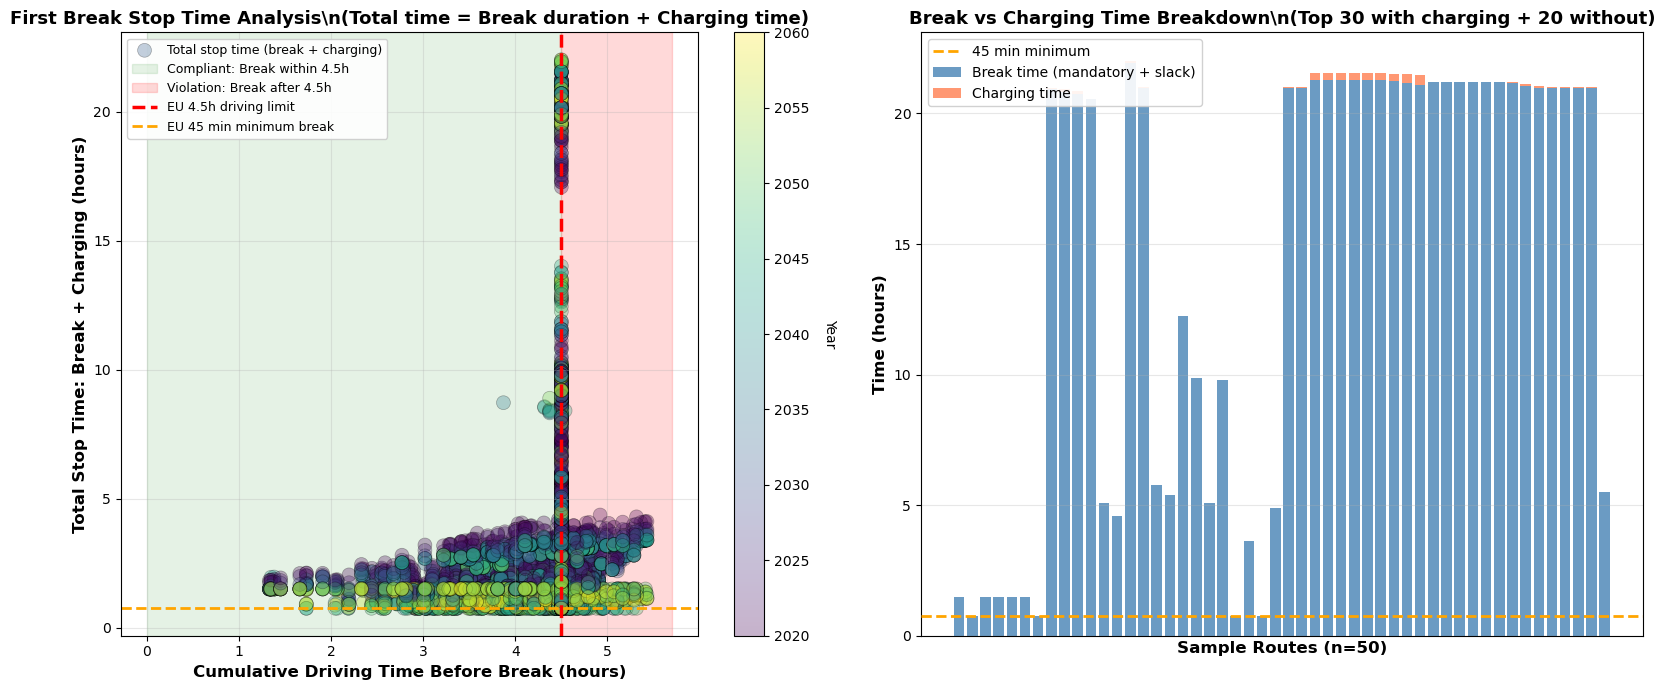

\nPlot saved as "break_timing_with_charging_analysis.png"
\nCompliance check:
  Routes with breaks within 4.5h: 5445/6894 (79.0%)
  Routes with breaks AFTER 4.5h: 1246/6894 (18.1%)
\nCharging impact:
  Routes with charging at break: 5702 (82.7%)
  Avg charging time (when charging): 1.00h (60 min)
  Max total stop time: 22.01h (1320 min)


In [23]:
# Visualization: Break Timing vs Duration (with Charging Time)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# LEFT PLOT: Total stop time (break + charging)
scatter = ax1.scatter(df_timing["cumulative_driving_time"], 
                     df_timing["total_stop_time"],
                     c=df_timing["year"], 
                     cmap="viridis",
                     s=100, 
                     alpha=0.3,
                     edgecolors="black",
                     linewidth=0.5,
                     label="Total stop time (break + charging)")

# Add colorbar for years
cbar = plt.colorbar(scatter, ax=ax1)
cbar.set_label("Year", rotation=270, labelpad=20)

# Shading zones
ax1.axvspan(0, 4.5, alpha=0.1, color="green", label="Compliant: Break within 4.5h", zorder=0)
if df_timing["cumulative_driving_time"].max() > 4.5:
    ax1.axvspan(4.5, df_timing["cumulative_driving_time"].max() * 1.05, 
               alpha=0.15, color="red", label="Violation: Break after 4.5h", zorder=0)

# Mark the 4.5 hour regulatory threshold
ax1.axvline(x=4.5, color="red", linestyle="--", linewidth=2.5, 
           label="EU 4.5h driving limit", zorder=2)

# Mark the minimum required break duration (0.75h = 45 min)
ax1.axhline(y=0.75, color="orange", linestyle="--", linewidth=2,
           label="EU 45 min minimum break", zorder=2)

ax1.set_xlabel("Cumulative Driving Time Before Break (hours)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Total Stop Time: Break + Charging (hours)", fontsize=12, fontweight="bold")
ax1.set_title("First Break Stop Time Analysis\\n(Total time = Break duration + Charging time)", 
             fontsize=13, fontweight="bold")
ax1.legend(loc="upper left", fontsize=9, framealpha=0.9)
ax1.grid(True, alpha=0.3)

# RIGHT PLOT: Break vs Charging time breakdown
# Create stacked bars showing break and charging components
routes_with_charging = df_timing[df_timing["charging_time"] > 0.01].sort_values("total_stop_time", ascending=False).head(30)
routes_no_charging = df_timing[df_timing["charging_time"] <= 0.01].sample(min(20, len(df_timing[df_timing["charging_time"] <= 0.01])))
sample_routes = pd.concat([routes_with_charging, routes_no_charging]).sort_values("cumulative_driving_time")

x_pos = range(len(sample_routes))
ax2.bar(x_pos, sample_routes["actual_break_duration"], 
       label="Break time (mandatory + slack)", color="steelblue", alpha=0.8)
ax2.bar(x_pos, sample_routes["charging_time"], 
       bottom=sample_routes["actual_break_duration"],
       label="Charging time", color="coral", alpha=0.8)

# Add horizontal line at 0.75h
ax2.axhline(y=0.75, color="orange", linestyle="--", linewidth=2, 
           label="45 min minimum", zorder=10)

ax2.set_xlabel(f"Sample Routes (n={len(sample_routes)})", fontsize=12, fontweight="bold")
ax2.set_ylabel("Time (hours)", fontsize=12, fontweight="bold")
ax2.set_title("Break vs Charging Time Breakdown\\n(Top 30 with charging + 20 without)", 
             fontsize=13, fontweight="bold")
ax2.legend(loc="upper left", fontsize=10, framealpha=0.9)
ax2.grid(True, alpha=0.3, axis="y")
ax2.set_xticks([])  # Hide x-tick labels for clarity

plt.tight_layout()
plt.savefig("break_timing_with_charging_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("\\nPlot saved as \"break_timing_with_charging_analysis.png\"")
print(f"\\nCompliance check:")
compliant = df_timing[
    (df_timing["cumulative_driving_time"] <= 4.5) & 
    (df_timing["actual_break_duration"] >= 0.75)
]
print(f"  Routes with breaks within 4.5h: {len(compliant)}/{len(df_timing)} "
      f"({len(compliant)/len(df_timing)*100:.1f}%)")

over_limit = df_timing[df_timing["cumulative_driving_time"] > 4.5]
print(f"  Routes with breaks AFTER 4.5h: {len(over_limit)}/{len(df_timing)} "
      f"({len(over_limit)/len(df_timing)*100:.1f}%)")

print(f"\\nCharging impact:")
charging_routes = df_timing[df_timing["charging_time"] > 0.01]
print(f"  Routes with charging at break: {len(charging_routes)} ({len(charging_routes)/len(df_timing)*100:.1f}%)")
if len(charging_routes) > 0:
    print(f"  Avg charging time (when charging): {charging_routes['charging_time'].mean():.2f}h ({charging_routes['charging_time'].mean()*60:.0f} min)")
    print(f"  Max total stop time: {df_timing['total_stop_time'].max():.2f}h ({df_timing['total_stop_time'].max()*60:.0f} min)")


Text(0.98, 0.97, 'Statistics:\nMin: 0.75h (45 min)\nMax: 22.01h (1320 min)\nStd: 3.40h\n< 45 min: 8 (0.1%)\n> 2h: 2993 (43.4%)')

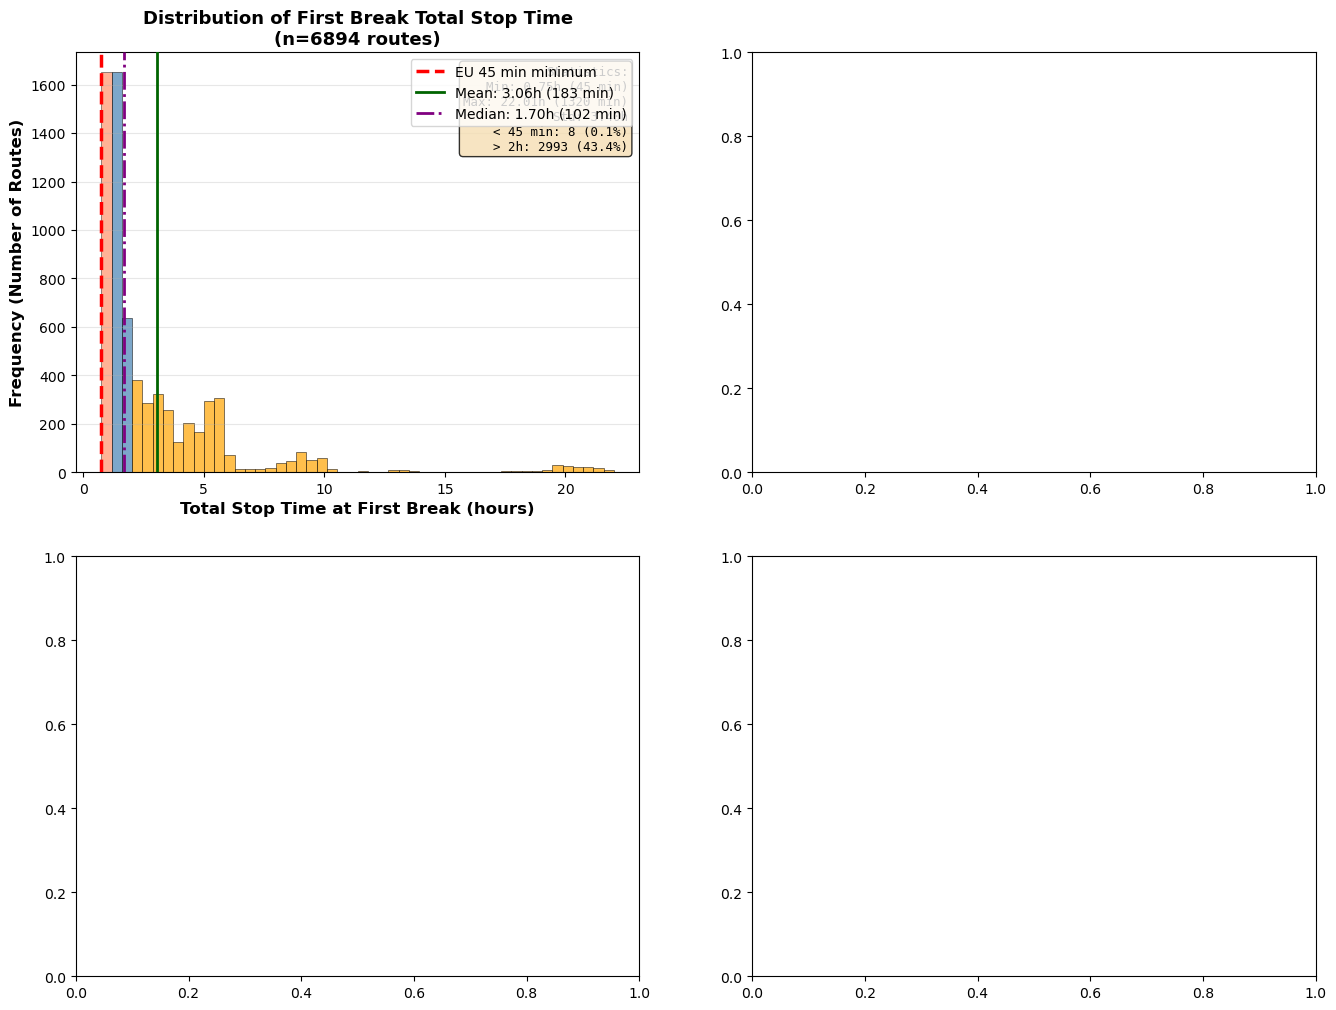

In [24]:

# ==============================================================================
# HISTOGRAM: FIRST BREAK TOTAL STOP TIME FREQUENCY
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ==============================================================================
# PLOT 1: Total Stop Time Distribution (Main histogram)
# ==============================================================================
ax1 = axes[0, 0]

# Create histogram
n, bins, patches = ax1.hist(df_timing["total_stop_time"],
                            bins=50,
                            color='steelblue',
                            alpha=0.7,
                            edgecolor='black',
                            linewidth=0.5)

# Color coding based on regulatory threshold (0.75h = 45 min)
for i, patch in enumerate(patches):
    if bins[i] < 0.75:
        patch.set_facecolor('coral')  # Below minimum (non-compliant)
        patch.set_alpha(0.6)
    elif bins[i] < 2.0:
        patch.set_facecolor('steelblue')  # Normal range
        patch.set_alpha(0.7)
    else:
        patch.set_facecolor('orange')  # Long stops (might be charging)
        patch.set_alpha(0.7)

# Add vertical line at regulatory minimum (45 min)
ax1.axvline(x=0.75, color='red', linestyle='--', linewidth=2.5,
           label='EU 45 min minimum', zorder=10)

# Add mean and median lines
mean_val = df_timing["total_stop_time"].mean()
median_val = df_timing["total_stop_time"].median()
ax1.axvline(x=mean_val, color='darkgreen', linestyle='-', linewidth=2,
           label=f'Mean: {mean_val:.2f}h ({mean_val*60:.0f} min)', zorder=10)
ax1.axvline(x=median_val, color='purple', linestyle='-.', linewidth=2,
           label=f'Median: {median_val:.2f}h ({median_val*60:.0f} min)', zorder=10)

ax1.set_xlabel('Total Stop Time at First Break (hours)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Frequency (Number of Routes)', fontsize=12, fontweight='bold')
ax1.set_title(f'Distribution of First Break Total Stop Time\n(n={len(df_timing)} routes)',
             fontsize=13, fontweight='bold')
ax1.legend(loc='upper right', fontsize=10)
ax1.grid(True, alpha=0.3, axis='y')

# Add text box with statistics
stats_text = f"""Statistics:
Min: {df_timing["total_stop_time"].min():.2f}h ({df_timing["total_stop_time"].min()*60:.0f} min)
Max: {df_timing["total_stop_time"].max():.2f}h ({df_timing["total_stop_time"].max()*60:.0f} min)
Std: {df_timing["total_stop_time"].std():.2f}h
< 45 min: {len(df_timing[df_timing["total_stop_time"] < 0.75])} ({len(df_timing[df_timing["total_stop_time"] < 0.75])/len(df_timing)*100:.1f}%)
> 2h: {len(df_timing[df_timing["total_stop_time"] > 2])} ({len(df_timing[df_timing["total_stop_time"] > 2])/len(df_timing)*100:.1f}%)"""

ax1.text(0.98, 0.97, stats_text,
        transform=ax1.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
        fontsize=9,
        family='monospace')


In [25]:
"""
QUICK CHECK: Why are there long breaks (>1.5h)?
Paste this into break_times.ipynb for immediate answers
"""

# ==============================================================================
# ISOLATE AND ANALYZE LONG STOPS
# ==============================================================================
import pandas as pd
import numpy as np
import re

threshold = 1.5  # hours
long_stops = df_timing[df_timing["total_stop_time"] > threshold].copy()

print("="*80)
print(f"LONG BREAKS INVESTIGATION (>{threshold}h)")
print("="*80)
print(f"\nFound: {len(long_stops)}/{len(df_timing)} routes ({len(long_stops)/len(df_timing)*100:.1f}%)")

# ==============================================================================
# QUESTION 1: Is it extra_break_time?
# ==============================================================================
print("\n" + "="*80)
print("Q1: IS IT EXTRA_BREAK_TIME?")
print("="*80)

# Get extra_break_time data
extra_break_data = loaded_runs[case_name]["output_data"].get("extra_break_time", {})

if extra_break_data and 'path_id' in long_stops.columns:
    from collections import defaultdict

    # Aggregate by path
    path_extra = defaultdict(float)

    for key, value in extra_break_data.items():
        if isinstance(value, str):
            value = float(value)
        if value > 0:
            # Parse path_id
            if isinstance(key, str):
                nums = re.findall(r'\d+', key)
                if len(nums) >= 4:
                    path_id = int(nums[2])
                    path_extra[path_id] = max(path_extra[path_id], value)
            else:
                path_id = key[1][2]
                path_extra[path_id] = max(path_extra[path_id], value)

    # Add to dataframe
    long_stops['extra_break_max'] = long_stops['path_id'].map(lambda p: path_extra.get(p, 0))

    print(f"\nRoutes with extra_break_time > 0: {len(long_stops[long_stops['extra_break_max'] > 0])}/{len(long_stops)}")
    print(f"Average extra_break_time: {long_stops['extra_break_max'].mean():.2f}h")
    print(f"Max extra_break_time: {long_stops['extra_break_max'].max():.2f}h")

    # Check if extra_break explains the long stops
    long_stops['extra_explains'] = long_stops['extra_break_max'] > 1.0

    print(f"\nRoutes where extra_break_time > 1h: {long_stops['extra_explains'].sum()}/{len(long_stops)}")

    if long_stops['extra_break_max'].mean() > 0.5:
        print("\n-> YES: Extra_break_time appears to be a major contributor!")
    else:
        print("\n-> NO: Extra_break_time is minimal, look elsewhere")
else:
    print("\n[INFO] extra_break_time data not available")

# ==============================================================================
# QUESTION 2: Is it coherent with mandatory breaks?
# ==============================================================================
print("\n" + "="*80)
print("Q2: IS IT COHERENT WITH MANDATORY BREAKS?")
print("="*80)

if 'path_id' in long_stops.columns:
    mandatory_breaks = loaded_runs[case_name]["input_data"]['MandatoryBreaks']
    breaks_dict = {}
    for mb in mandatory_breaks:
        if mb['path_id'] not in breaks_dict:
            breaks_dict[mb['path_id']] = []
        breaks_dict[mb['path_id']].append(mb)

    # Check top 5 worst cases
    print("\nTop 5 longest stops - checking mandatory break data:")
    print("-"*80)

    for idx, row in long_stops.nlargest(5, 'total_stop_time').iterrows():
        path_id = row['path_id']
        total_stop = row['total_stop_time']
        break_dur = row.get('actual_break_duration', 0)
        charging = row.get('charging_time', 0)

        print(f"\nPath {path_id}: Total={total_stop:.2f}h (Break={break_dur:.2f}h, Charge={charging:.2f}h)")

        # Mandatory break info
        if path_id in breaks_dict:
            first_break = breaks_dict[path_id][0]
            print(f"  Mandatory break #1: time_with_breaks={first_break['time_with_breaks']:.2f}h")
            print(f"  Actual break duration: {break_dur:.2f}h")
            print(f"  Difference: {break_dur - first_break['time_with_breaks']:.2f}h")

            if break_dur > first_break['time_with_breaks'] + 0.5:
                print(f"  -> INCOHERENT: {break_dur - first_break['time_with_breaks']:.2f}h EXTRA beyond mandatory!")
            else:
                print(f"  -> Coherent with mandatory break")
        else:
            print(f"  No mandatory break (path < 360km)")
            if break_dur > 1.0:
                print(f"  -> STRANGE: {break_dur:.2f}h break for short route!")

# ==============================================================================
# QUESTION 3: Are these long distance routes?
# ==============================================================================
print("\n" + "="*80)
print("Q3: ARE THESE LONG DISTANCE ROUTES?")
print("="*80)

if 'path_id' in long_stops.columns:
    paths = loaded_runs[case_name]["input_data"]['Path']
    paths_dict = {p['id']: p for p in paths}

    # Add path characteristics
    long_stops['path_length'] = long_stops['path_id'].map(lambda p: paths_dict.get(p, {}).get('length', np.nan))
    long_stops['num_nodes'] = long_stops['path_id'].map(lambda p: len(paths_dict.get(p, {}).get('sequence', [])))

    # Compare with all routes
    all_lengths = [paths_dict[pid]['length'] for pid in df_timing['path_id'].unique() if pid in paths_dict]

    print(f"\nPath length comparison:")
    print(f"  All routes:       Mean={np.mean(all_lengths):.1f}km, Median={np.median(all_lengths):.1f}km")
    print(f"  Long stop routes: Mean={long_stops['path_length'].mean():.1f}km, Median={long_stops['path_length'].median():.1f}km")
    print(f"  Difference:       {long_stops['path_length'].mean() - np.mean(all_lengths):.1f}km ({(long_stops['path_length'].mean() - np.mean(all_lengths))/np.mean(all_lengths)*100:.1f}%)")

    if long_stops['path_length'].mean() > np.mean(all_lengths) * 1.2:
        print("\n-> YES: Long stop routes are SIGNIFICANTLY LONGER")
    elif long_stops['path_length'].mean() > np.mean(all_lengths) * 1.05:
        print("\n-> SOMEWHAT: Long stop routes are slightly longer")
    else:
        print("\n-> NO: Long stop routes are NOT particularly longer")

    # Distribution
    print(f"\nDistance distribution for long stop routes:")
    bins = [0, 360, 720, 1000, 1500, 10000]
    labels = ['<360km', '360-720km', '720-1000km', '1000-1500km', '>1500km']
    long_stops['distance_bin'] = pd.cut(long_stops['path_length'], bins=bins, labels=labels)

    for label in labels:
        count = len(long_stops[long_stops['distance_bin'] == label])
        if count > 0:
            pct = count / len(long_stops) * 100
            avg_stop = long_stops[long_stops['distance_bin'] == label]['total_stop_time'].mean()
            print(f"  {label:15s}: {count:3d} routes ({pct:4.1f}%) - Avg stop: {avg_stop:.2f}h")

# ==============================================================================
# QUESTION 4: What's the breakdown?
# ==============================================================================
print("\n" + "="*80)
print("Q4: WHAT'S THE BREAKDOWN?")
print("="*80)

if 'charging_time' in long_stops.columns and 'actual_break_duration' in long_stops.columns:
    total_stop_sum = long_stops['total_stop_time'].sum()
    break_sum = long_stops['actual_break_duration'].sum()
    charging_sum = long_stops['charging_time'].sum()

    print(f"\nTotal time breakdown for {len(long_stops)} routes with stops > {threshold}h:")
    print(f"  Total stop time:   {total_stop_sum:.1f}h (100%)")
    print(f"  Break duration:    {break_sum:.1f}h ({break_sum/total_stop_sum*100:.1f}%)")
    print(f"  Charging time:     {charging_sum:.1f}h ({charging_sum/total_stop_sum*100:.1f}%)")

    # Categorize routes
    charging_dominant = long_stops[long_stops['charging_time'] / long_stops['total_stop_time'] > 0.5]
    break_dominant = long_stops[long_stops['actual_break_duration'] / long_stops['total_stop_time'] > 0.5]

    print(f"\nRoute categorization:")
    print(f"  Charging-dominant (>50% charging): {len(charging_dominant)} ({len(charging_dominant)/len(long_stops)*100:.1f}%)")
    print(f"  Break-dominant (>50% break):      {len(break_dominant)} ({len(break_dominant)/len(long_stops)*100:.1f}%)")

    if len(charging_dominant) > len(break_dominant):
        print("\n-> CHARGING is the main cause of long stops")
    else:
        print("\n-> BREAK DURATION (incl. extra_break_time) is the main cause")

# ==============================================================================
# FINAL ANSWER
# ==============================================================================
print("\n" + "="*80)
print("FINAL ANSWER: WHERE DO LONG BREAKS COME FROM?")
print("="*80)

causes = []

if 'extra_break_max' in long_stops.columns:
    if long_stops['extra_break_max'].mean() > 0.5:
        causes.append(f"Extra_break_time (avg {long_stops['extra_break_max'].mean():.2f}h)")

if 'charging_time' in long_stops.columns:
    if long_stops['charging_time'].mean() > 0.5:
        causes.append(f"Charging time (avg {long_stops['charging_time'].mean():.2f}h)")

if 'path_length' in long_stops.columns:
    if long_stops['path_length'].mean() > np.mean(all_lengths) * 1.2:
        causes.append(f"Longer routes (avg {long_stops['path_length'].mean():.1f}km)")

print("\nMain contributors to long breaks:")
for i, cause in enumerate(causes, 1):
    print(f"  {i}. {cause}")

if not causes:
    print("  [UNCLEAR] - Need deeper investigation")

print("\n" + "="*80)

# Create summary dataframe
summary = long_stops[['path_id', 'total_stop_time', 'actual_break_duration', 'charging_time']].copy()
if 'extra_break_max' in long_stops.columns:
    summary['extra_break_max'] = long_stops['extra_break_max']
if 'path_length' in long_stops.columns:
    summary['path_length'] = long_stops['path_length']

print("\nTop 10 longest stops with full details:")
print(summary.nlargest(10, 'total_stop_time').to_string())

LONG BREAKS INVESTIGATION (>1.5h)

Found: 4014/6894 routes (58.2%)

Q1: IS IT EXTRA_BREAK_TIME?

Routes with extra_break_time > 0: 3845/4014
Average extra_break_time: 223.58h
Max extra_break_time: 3234.63h

Routes where extra_break_time > 1h: 3845/4014

-> YES: Extra_break_time appears to be a major contributor!

Q2: IS IT COHERENT WITH MANDATORY BREAKS?

Top 5 longest stops - checking mandatory break data:
--------------------------------------------------------------------------------

Path 705: Total=22.01h (Break=21.94h, Charge=0.07h)
  Mandatory break #1: time_with_breaks=5.25h
  Actual break duration: 21.94h
  Difference: 16.69h
  -> INCOHERENT: 16.69h EXTRA beyond mandatory!

Path 642: Total=22.00h (Break=22.00h, Charge=0.00h)
  Mandatory break #1: time_with_breaks=5.25h
  Actual break duration: 22.00h
  Difference: 16.75h
  -> INCOHERENT: 16.75h EXTRA beyond mandatory!

Path 705: Total=21.94h (Break=21.94h, Charge=0.00h)
  Mandatory break #1: time_with_breaks=5.25h
  Actual bre

In [26]:
# Analysis: Why are some stops so long?
# Breakdown of the longest stops

print("="*80)
print("ANALYSIS: LONGEST STOP TIMES")
print("="*80)

# Get top 10 longest stops
longest_stops = df_timing.nlargest(10, "total_stop_time")

print(f"\nTop 10 longest stops (out of {len(df_timing)} first breaks):")
print()
for idx, row in longest_stops.iterrows():
    print(f"Route {row['path_id']}, Year {row['year']}, Gen {row['generation']}, TV {row['vehicle_type']}")
    print(f"  Driving before break:  {row['cumulative_driving_time']:.2f}h ({row['cumulative_driving_time']*60:.0f} min)")
    print(f"  Mandatory break:       {row['min_break_duration']:.2f}h ({row['min_break_duration']*60:.0f} min) [REQUIRED]")
    print(f"  Extra slack:           {row['extra_slack']:.2f}h ({row['extra_slack']*60:.0f} min) [OPTIMIZER ADDED]")
    print(f"  Actual break total:    {row['actual_break_duration']:.2f}h ({row['actual_break_duration']*60:.0f} min)")
    print(f"  Charging time:         {row['charging_time']:.2f}h ({row['charging_time']*60:.0f} min) [CHARGING]")
    print(f"  TOTAL STOP TIME:       {row['total_stop_time']:.2f}h ({row['total_stop_time']*60:.0f} min)")
    
    # Calculate percentages
    total = row["total_stop_time"]
    if total > 0:
        pct_mandatory = (row["min_break_duration"] / total) * 100
        pct_slack = (row["extra_slack"] / total) * 100
        pct_charging = (row["charging_time"] / total) * 100
        print(f"  Breakdown: {pct_mandatory:.1f}% mandatory, {pct_slack:.1f}% slack, {pct_charging:.1f}% charging")
    print()

# Summary statistics
print("="*80)
print("OVERALL STATISTICS")
print("="*80)
print(f"\nAll {len(df_timing)} first breaks:")
print(f"  Avg mandatory break:  {df_timing['min_break_duration'].mean():.2f}h ({df_timing['min_break_duration'].mean()*60:.0f} min)")
print(f"  Avg extra slack:      {df_timing['extra_slack'].mean():.2f}h ({df_timing['extra_slack'].mean()*60:.0f} min)")
print(f"  Avg charging:         {df_timing['charging_time'].mean():.2f}h ({df_timing['charging_time'].mean()*60:.0f} min)")
print(f"  Avg total stop:       {df_timing['total_stop_time'].mean():.2f}h ({df_timing['total_stop_time'].mean()*60:.0f} min)")

# What's driving the cost?
print(f"\nWhat makes stops long?")
total_time_all = df_timing['total_stop_time'].sum()
mandatory_all = df_timing['min_break_duration'].sum()
slack_all = df_timing['extra_slack'].sum()
charging_all = df_timing['charging_time'].sum()

print(f"  Mandatory breaks:  {(mandatory_all/total_time_all)*100:.1f}% of total stop time")
print(f"  Extra slack:       {(slack_all/total_time_all)*100:.1f}% of total stop time")
print(f"  Charging:          {(charging_all/total_time_all)*100:.1f}% of total stop time")

# Distribution
print(f"\nDistribution of stop times:")
print(f"  < 1h:   {(df_timing['total_stop_time'] < 1.0).sum()} routes ({(df_timing['total_stop_time'] < 1.0).sum()/len(df_timing)*100:.1f}%)")
print(f"  1-2h:   {((df_timing['total_stop_time'] >= 1.0) & (df_timing['total_stop_time'] < 2.0)).sum()} routes")
print(f"  2-3h:   {((df_timing['total_stop_time'] >= 2.0) & (df_timing['total_stop_time'] < 3.0)).sum()} routes")
print(f"  > 3h:   {(df_timing['total_stop_time'] >= 3.0).sum()} routes")

# Are long stops due to slack or charging?
long_stops = df_timing[df_timing['total_stop_time'] > 1.5]
if len(long_stops) > 0:
    print(f"\nFor stops > 1.5h ({len(long_stops)} routes):")
    print(f"  Avg slack:    {long_stops['extra_slack'].mean():.2f}h ({long_stops['extra_slack'].mean()*60:.0f} min)")
    print(f"  Avg charging: {long_stops['charging_time'].mean():.2f}h ({long_stops['charging_time'].mean()*60:.0f} min)")
    print(f"  Main driver: {'CHARGING' if long_stops['charging_time'].mean() > long_stops['extra_slack'].mean() else 'SLACK'}")


ANALYSIS: LONGEST STOP TIMES

Top 10 longest stops (out of 6894 first breaks):

Route 705.0, Year 2056.0, Gen 2056.0, TV 1.0
  Driving before break:  4.50h (270 min)
  Mandatory break:       0.75h (45 min) [REQUIRED]
  Extra slack:           21.19h (1271 min) [OPTIMIZER ADDED]
  Actual break total:    21.94h (1316 min)
  Charging time:         0.07h (4 min) [CHARGING]
  TOTAL STOP TIME:       22.01h (1320 min)
  Breakdown: 3.4% mandatory, 96.3% slack, 0.3% charging

Route 642.0, Year 2048.0, Gen 2048.0, TV 1.0
  Driving before break:  4.50h (270 min)
  Mandatory break:       0.75h (45 min) [REQUIRED]
  Extra slack:           21.25h (1275 min) [OPTIMIZER ADDED]
  Actual break total:    22.00h (1320 min)
  Charging time:         0.00h (0 min) [CHARGING]
  TOTAL STOP TIME:       22.00h (1320 min)
  Breakdown: 3.4% mandatory, 96.6% slack, 0.0% charging

Route 705.0, Year 2052.0, Gen 2052.0, TV 1.0
  Driving before break:  4.50h (270 min)
  Mandatory break:       0.75h (45 min) [REQUIRED]
 

In [27]:
# Cumulative Break Time Analysis
# Calculate total break time accumulated along each route

# Group mandatory breaks by path_id and num_drivers
from collections import defaultdict

path_breaks = defaultdict(list)
for mb in mandatory_breaks:
    if mb.get("num_drivers") == 1:  # Only single-driver routes
        path_id = mb["path_id"]
        path_breaks[path_id].append(mb)

# Sort breaks by break_number for each path
for path_id in path_breaks:
    path_breaks[path_id].sort(key=lambda x: x.get("break_number", 0))

print(f"Found {len(path_breaks)} paths with breaks")

# Calculate cumulative break times from input data AND optimization results
cumulative_break_data = []

for path_id, breaks in path_breaks.items():
    cumulative_mandatory_time = 0.0
    cumulative_actual_time = 0.0
    
    path = path_dict.get(path_id)
    if not path:
        continue
    
    for mb in breaks:
        # Mandatory break time from input data
        cumulative_driving_time = mb["cumulative_driving_time"]
        time_with_breaks = mb["time_with_breaks"]
        this_mandatory_duration = time_with_breaks - cumulative_driving_time
        cumulative_mandatory_time += this_mandatory_duration
        
        # Get actual break duration from optimization results
        # actual = mandatory + slack (extra_break_time)
        break_location = mb["latest_geo_id"]
        extra_break_slack = 0.0
        
        # Find matching travel_time entries for this break location
        for key, tt_value in travel_time.items():
            year, prkg, tv_id, gen = key
            prod_id, od_id, key_path_id, geo_id = prkg
            
            if key_path_id == path_id and geo_id == break_location:
                # Get flow to calculate number of vehicles
                flow_key = (year, (prod_id, od_id, path_id), (1, tv_id), gen)
                flow_val = flow.get(flow_key, 0)
                
                if flow_val < 1e-6:
                    continue
                
                # Calculate number of vehicles
                tv = tv_dict.get(tv_id)
                if not tv:
                    continue
                
                gen_idx = gen - g_init
                W = tv["W"][gen_idx]
                AnnualRange = tv["AnnualRange"][gen_idx]
                
                num_vehicles = (path["length"] / (W * AnnualRange)) * 1000 * flow_val
                
                # Get slack from extra_break_time (per vehicle)
                extra_key = (year, prkg, tv_id, gen)
                extra_time = extra_break_time.get(extra_key, 0)
                extra_break_slack = extra_time / num_vehicles if num_vehicles > 0 else 0
                break  # Use first matching entry
        
        # CORRECTED: Actual break = mandatory + slack
        this_actual_duration = this_mandatory_duration + extra_break_slack
        cumulative_actual_time += this_actual_duration
        
        cumulative_break_data.append({
            "path_id": path_id,
            "break_number": mb["break_number"],
            "event_type": mb["event_type"],
            "cumulative_driving_time": cumulative_driving_time,
            "this_mandatory_duration": this_mandatory_duration,
            "extra_slack": extra_break_slack,
            "this_actual_duration": this_actual_duration,
            "cumulative_mandatory_time": cumulative_mandatory_time,
            "cumulative_actual_time": cumulative_actual_time,
            "total_time_mandatory": cumulative_driving_time + cumulative_mandatory_time,
            "total_time_actual": cumulative_driving_time + cumulative_actual_time
        })

df_cumulative = pd.DataFrame(cumulative_break_data)
print(f"Analyzed {len(df_cumulative)} cumulative break points")
print(f"\nCumulative break statistics:")
print(f"  Max cumulative mandatory breaks: {df_cumulative['cumulative_mandatory_time'].max():.2f}h")
print(f"  Max cumulative actual breaks (with slack): {df_cumulative['cumulative_actual_time'].max():.2f}h")
print(f"  Avg mandatory breaks per path: {df_cumulative.groupby('path_id')['cumulative_mandatory_time'].max().mean():.2f}h")
print(f"  Avg actual breaks per path: {df_cumulative.groupby('path_id')['cumulative_actual_time'].max().mean():.2f}h")
print(f"  Max driving time: {df_cumulative['cumulative_driving_time'].max():.2f}h")


Found 582 paths with breaks
Analyzed 949 cumulative break points

Cumulative break statistics:
  Max cumulative mandatory breaks: 12.00h
  Max cumulative actual breaks (with slack): 41.99h
  Avg mandatory breaks per path: 2.33h
  Avg actual breaks per path: 4.57h
  Max driving time: 22.50h


In [28]:
# Display sample of break analysis
print("\n" + "="*80)
print("SAMPLE BREAK ANALYSIS (First 10 entries)")
print("="*80)

display_cols = ["path_id", "year", "num_vehicles", "min_required_time", 
                "actual_travel_time", "slack_per_vehicle", "compliance"]
print(df_breaks[display_cols].head(10).to_string(index=False))


SAMPLE BREAK ANALYSIS (First 10 entries)
 path_id  year  num_vehicles  min_required_time  actual_travel_time  slack_per_vehicle compliance
       2  2032     27.754640          81.515827           99.489647           0.000000         OK
       2  2044     35.963749         105.626114          105.626113           0.000000         OK
       2  2020     23.141906          67.968152           91.760580           0.000000         OK
       2  2048     35.074088         103.013166          103.013166           0.535436         OK
       2  2052     34.299223         100.737373          100.737373           0.541082         OK
       2  2024     24.679484          72.484043           94.106802           0.000000         OK
       2  2028     26.217062          76.999935           95.976335           0.000000         OK
       2  2036     29.292218          86.031718          105.001270           0.000000         OK
       2  2040     36.995755         108.657132          108.657132         

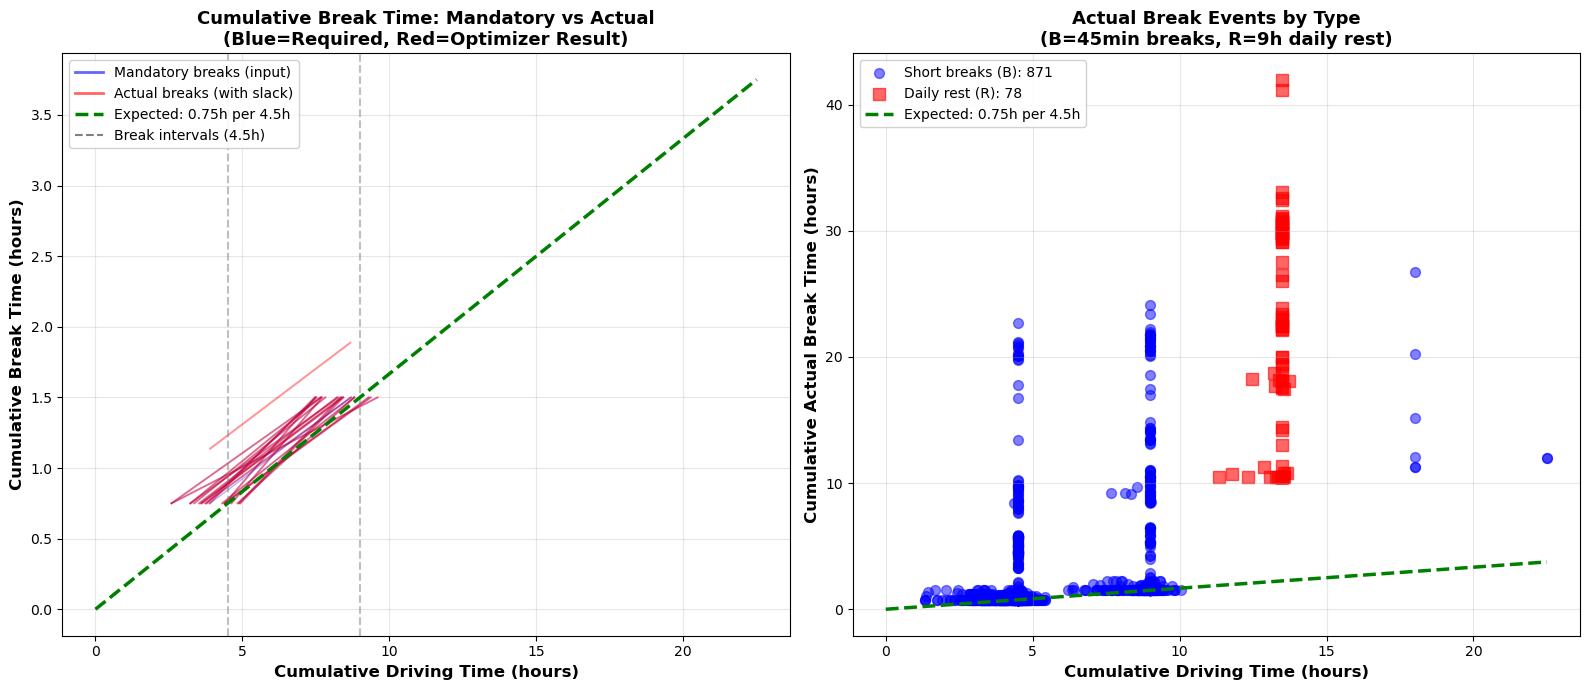

\nPlot saved as "cumulative_break_time_analysis.png"
\nKey insights:
  Total break events: 949
  Short breaks (B): 871 (91.8%)
  Daily rests (R): 78 (8.2%)
  Paths with multiple breaks: 281
\nBreak time comparison:
  Avg mandatory break per event: 1.428h (85.7 min)
  Avg actual break per event: 2.802h (168.1 min)
  Avg extra slack per break: 1.374h (82.4 min)
  Total slack = Actual - Mandatory: 1303.67h


In [29]:
# Visualization: Cumulative Break Time vs Driving Time
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# LEFT PLOT: Mandatory vs Actual cumulative break times
for path_id in df_cumulative["path_id"].unique()[:50]:  # Show first 50 paths for clarity
    path_data = df_cumulative[df_cumulative["path_id"] == path_id]
    # Mandatory breaks (thin line)
    ax1.plot(path_data["cumulative_driving_time"], 
            path_data["cumulative_mandatory_time"],
            color="blue", alpha=0.3, linewidth=1, linestyle="-")
    # Actual breaks with slack (thicker line)
    ax1.plot(path_data["cumulative_driving_time"], 
            path_data["cumulative_actual_time"],
            color="red", alpha=0.4, linewidth=1.5, linestyle="-")

# Add reference lines for EU regulations
max_driving = df_cumulative["cumulative_driving_time"].max()
ax1.axvline(x=4.5, color="gray", linestyle="--", linewidth=1.5, alpha=0.5, label="Break intervals (4.5h)")
ax1.axvline(x=9.0, color="gray", linestyle="--", linewidth=1.5, alpha=0.5)

# Expected cumulative break time line (0.75h per 4.5h of driving)
driving_range = np.linspace(0, max_driving, 100)
expected_breaks = (driving_range / 4.5) * 0.75
ax1.plot(driving_range, expected_breaks, "g--", linewidth=2.5, label="Expected: 0.75h per 4.5h", zorder=10)

# Legend entries for line types
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color="blue", linewidth=2, alpha=0.6, label="Mandatory breaks (input)"),
    Line2D([0], [0], color="red", linewidth=2, alpha=0.6, label="Actual breaks (with slack)"),
    Line2D([0], [0], color="green", linewidth=2.5, linestyle="--", label="Expected: 0.75h per 4.5h"),
    Line2D([0], [0], color="gray", linewidth=1.5, linestyle="--", label="Break intervals (4.5h)")
]
ax1.legend(handles=legend_elements, loc="upper left", fontsize=10, framealpha=0.9)

ax1.set_xlabel("Cumulative Driving Time (hours)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Cumulative Break Time (hours)", fontsize=12, fontweight="bold")
ax1.set_title("Cumulative Break Time: Mandatory vs Actual\n(Blue=Required, Red=Optimizer Result)", 
             fontsize=13, fontweight="bold")
ax1.grid(True, alpha=0.3)

# RIGHT PLOT: Actual break times colored by event type
break_events = df_cumulative[df_cumulative["event_type"] == "B"]
rest_events = df_cumulative[df_cumulative["event_type"] == "R"]

if len(break_events) > 0:
    ax2.scatter(break_events["cumulative_driving_time"], 
               break_events["cumulative_actual_time"],
               c="blue", s=50, alpha=0.5, label=f"Short breaks (B): {len(break_events)}")

if len(rest_events) > 0:
    ax2.scatter(rest_events["cumulative_driving_time"], 
               rest_events["cumulative_actual_time"],
               c="red", s=80, alpha=0.6, marker="s", label=f"Daily rest (R): {len(rest_events)}")

# Expected cumulative break time line
ax2.plot(driving_range, expected_breaks, "g--", linewidth=2.5, label="Expected: 0.75h per 4.5h", zorder=10)

ax2.set_xlabel("Cumulative Driving Time (hours)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Cumulative Actual Break Time (hours)", fontsize=12, fontweight="bold")
ax2.set_title("Actual Break Events by Type\n(B=45min breaks, R=9h daily rest)", 
             fontsize=13, fontweight="bold")
ax2.legend(loc="upper left", fontsize=10, framealpha=0.9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("cumulative_break_time_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("\\nPlot saved as \"cumulative_break_time_analysis.png\"")
print(f"\\nKey insights:")
print(f"  Total break events: {len(df_cumulative)}")
print(f"  Short breaks (B): {len(break_events)} ({len(break_events)/len(df_cumulative)*100:.1f}%)")
print(f"  Daily rests (R): {len(rest_events)} ({len(rest_events)/len(df_cumulative)*100:.1f}%)")
print(f"  Paths with multiple breaks: {sum(df_cumulative.groupby('path_id')['break_number'].max() > 1)}")
print(f"\\nBreak time comparison:")
print(f"  Avg mandatory break per event: {df_cumulative['this_mandatory_duration'].mean():.3f}h ({df_cumulative['this_mandatory_duration'].mean()*60:.1f} min)")
print(f"  Avg actual break per event: {df_cumulative['this_actual_duration'].mean():.3f}h ({df_cumulative['this_actual_duration'].mean()*60:.1f} min)")
print(f"  Avg extra slack per break: {df_cumulative['extra_slack'].mean():.3f}h ({df_cumulative['extra_slack'].mean()*60:.1f} min)")
print(f"  Total slack = Actual - Mandatory: {(df_cumulative['this_actual_duration'] - df_cumulative['this_mandatory_duration']).sum():.2f}h")


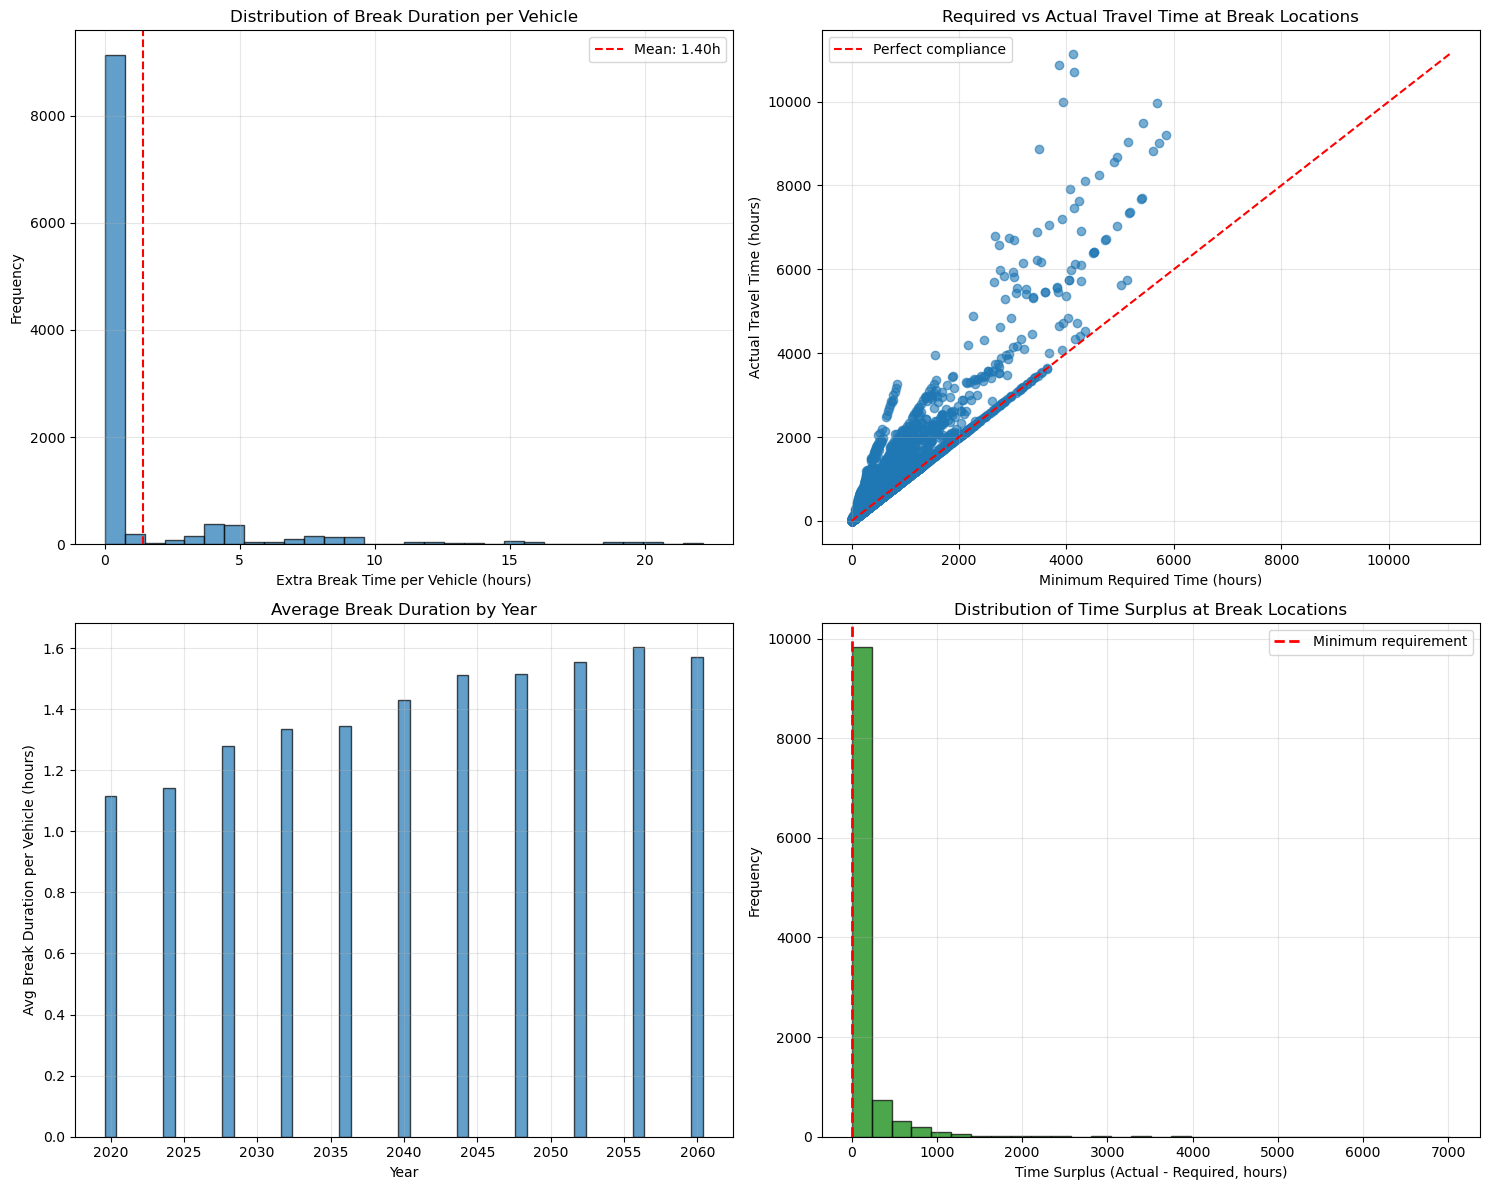


Plot saved as 'break_times_analysis.png'


In [30]:
# Visualization: Break duration distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Break duration per vehicle distribution
ax = axes[0, 0]
ax.hist(df_breaks["slack_per_vehicle"], bins=30, edgecolor="black", alpha=0.7)
ax.set_xlabel("Extra Break Time per Vehicle (hours)")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Break Duration per Vehicle")
ax.axvline(df_breaks["slack_per_vehicle"].mean(), color="red", linestyle="--", label=f'Mean: {df_breaks["slack_per_vehicle"].mean():.2f}h')
ax.legend()
ax.grid(True, alpha=0.3)

# 2. Required vs Actual time
ax = axes[0, 1]
ax.scatter(df_breaks["min_required_time"], df_breaks["actual_travel_time"], alpha=0.6)
max_val = max(df_breaks["min_required_time"].max(), df_breaks["actual_travel_time"].max())
ax.plot([0, max_val], [0, max_val], "r--", label="Perfect compliance")
ax.set_xlabel("Minimum Required Time (hours)")
ax.set_ylabel("Actual Travel Time (hours)")
ax.set_title("Required vs Actual Travel Time at Break Locations")
ax.legend()
ax.grid(True, alpha=0.3)

# 3. Break duration by year
ax = axes[1, 0]
yearly_avg = df_breaks.groupby("year")["slack_per_vehicle"].mean()
ax.bar(yearly_avg.index, yearly_avg.values, edgecolor="black", alpha=0.7)
ax.set_xlabel("Year")
ax.set_ylabel("Avg Break Duration per Vehicle (hours)")
ax.set_title("Average Break Duration by Year")
ax.grid(True, alpha=0.3)

# 4. Time surplus distribution
ax = axes[1, 1]
ax.hist(df_breaks["time_difference"], bins=30, edgecolor="black", alpha=0.7, color="green")
ax.axvline(0, color="red", linestyle="--", linewidth=2, label="Minimum requirement")
ax.set_xlabel("Time Surplus (Actual - Required, hours)")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Time Surplus at Break Locations")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("break_times_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nPlot saved as 'break_times_analysis.png'")

In [31]:
# Check for any violations
violations = df_breaks[df_breaks["compliance"] == "VIOLATION"]

if len(violations) > 0:
    print("\n" + "="*80)
    print(f"WARNING: {len(violations)} VIOLATIONS FOUND")
    print("="*80)
    print("\nDetails of violations:")
    print(violations[["path_id", "year", "num_vehicles", "min_required_time", 
                     "actual_travel_time", "time_difference"]].to_string(index=False))
else:
    print("\n" + "="*80)
    print("ALL BREAK REQUIREMENTS MET - NO VIOLATIONS")
    print("="*80)


ALL BREAK REQUIREMENTS MET - NO VIOLATIONS
